Dataset shape: (144, 1)
Number of records: 144
Training sequences: 107
Testing sequences: 27
Data preparation completed.

Training Bidirectional RNN...
Epoch 5/30, Loss: 0.00515
Epoch 10/30, Loss: 0.00422
Epoch 15/30, Loss: 0.00247
Epoch 20/30, Loss: 0.00209
Epoch 25/30, Loss: 0.00196
Epoch 30/30, Loss: 0.00182

Training Feedforward Neural Network...
Epoch 5/30, Loss: 0.00382
Epoch 10/30, Loss: 0.00398
Epoch 15/30, Loss: 0.00211
Epoch 20/30, Loss: 0.00190
Epoch 25/30, Loss: 0.00163
Epoch 30/30, Loss: 0.00283

Model Performance
BiRNN MSE: 1589.553
FFNN MSE: 1516.516


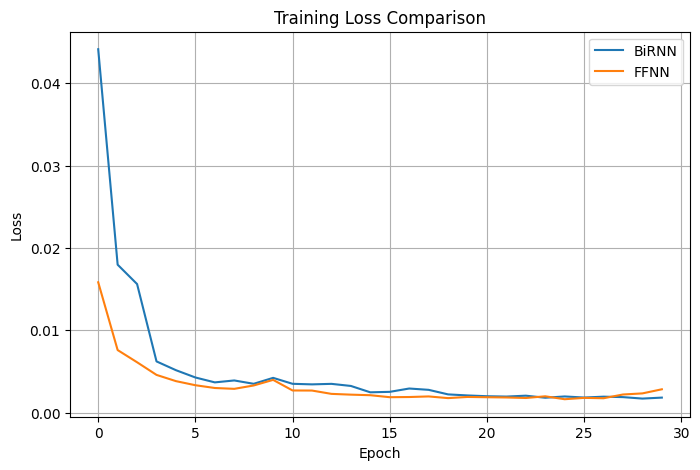

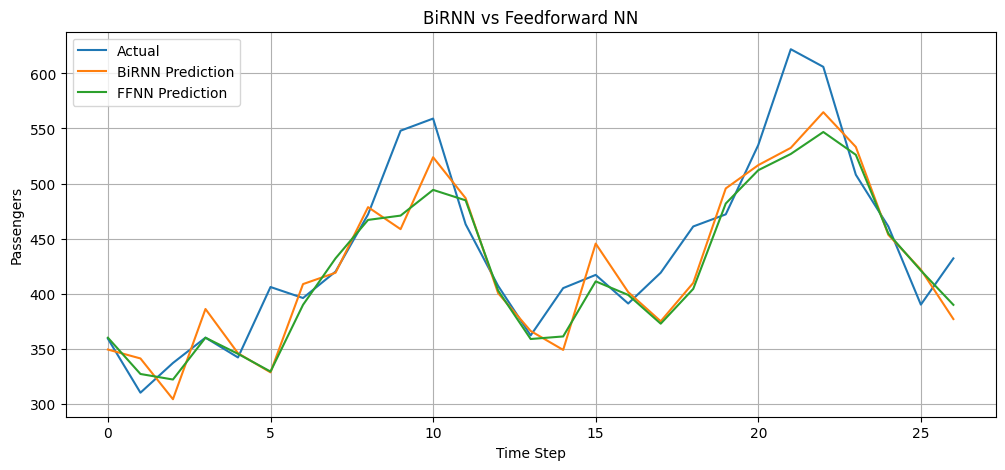


Final Comparison
FFNN performed better.
BiRNN MSE : 1589.553
FFNN MSE  : 1516.516


In [ ]:
# ==========================================
# Exp-6: Bidirectional RNN vs Feedforward NN for Time-Series Prediction
# ==========================================

# Step 1: Import Necessary Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader


# Step 2: Load and Preprocess the Dataset

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-airline-passengers.csv"

df = pd.read_csv(
    url,
    usecols=[1]
)

data = df.values.astype("float32")

scaler = MinMaxScaler(
    feature_range=(0, 1)
)

data_scaled = scaler.fit_transform(data)

print("Dataset shape:", data.shape)
print("Number of records:", len(data))


# Step 3: Create Time-Series Sequences

SEQ_LENGTH = 10

X = []
y = []

for i in range(
    len(data_scaled) - SEQ_LENGTH
):

    X.append(
        data_scaled[
            i:i + SEQ_LENGTH
        ]
    )

    y.append(
        data_scaled[
            i + SEQ_LENGTH
        ]
    )

X = np.array(X)
y = np.array(y)

# Split into training and testing data
train_size = int(
    len(X) * 0.8
)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training sequences:", len(X_train))
print("Testing sequences:", len(X_test))


# Step 4: Prepare PyTorch DataLoaders

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
)

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

print("Data preparation completed.")


# Step 5: Define the Bidirectional RNN

class BiRNN(nn.Module):

    def __init__(
        self,
        input_size=1,
        hidden_size=32
    ):

        super(BiRNN, self).__init__()

        self.rnn = nn.RNN(
            input_size,
            hidden_size,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(
            hidden_size * 2,
            1
        )

    def forward(self, x):

        output, _ = self.rnn(x)

        # Use the last time step
        output = output[:, -1, :]

        return self.fc(output)


# Step 6: Define the Feedforward Neural Network

class FeedforwardNN(nn.Module):

    def __init__(
        self,
        input_size
    ):

        super(FeedforwardNN, self).__init__()

        self.fc1 = nn.Linear(
            input_size,
            32
        )

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(
            32,
            1
        )

    def forward(self, x):

        # Flatten sequence
        x = x.view(
            x.size(0),
            -1
        )

        x = self.relu(
            self.fc1(x)
        )

        return self.fc2(x)


# Step 7: Define the Training Function

def train_model(
    model,
    loader,
    epochs=30
):

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01
    )

    losses = []

    model.train()

    for epoch in range(epochs):

        total_loss = 0

        for sequences, targets in loader:

            optimizer.zero_grad()

            outputs = model(
                sequences
            )

            loss = criterion(
                outputs,
                targets
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        average_loss = (
            total_loss / len(loader)
        )

        losses.append(
            average_loss
        )

        if (epoch + 1) % 5 == 0:

            print(
                f"Epoch {epoch + 1}/{epochs}, "
                f"Loss: {average_loss:.5f}"
            )

    return losses


# Step 8: Train the Bidirectional RNN

print("\nTraining Bidirectional RNN...")

birnn = BiRNN()

birnn_losses = train_model(
    birnn,
    train_loader,
    epochs=30
)


# Step 9: Train the Feedforward Neural Network

print("\nTraining Feedforward Neural Network...")

ffnn = FeedforwardNN(
    input_size=SEQ_LENGTH
)

ffnn_losses = train_model(
    ffnn,
    train_loader,
    epochs=30
)


# Step 10: Generate Predictions

birnn.eval()
ffnn.eval()

with torch.no_grad():

    pred_birnn = birnn(
        X_test_tensor
    ).numpy()

    pred_ffnn = ffnn(
        X_test_tensor
    ).numpy()


# Step 11: Convert Predictions Back to Original Scale

pred_birnn_inv = scaler.inverse_transform(
    pred_birnn
)

pred_ffnn_inv = scaler.inverse_transform(
    pred_ffnn
)

y_test_inv = scaler.inverse_transform(
    y_test
)


# Step 12: Calculate Mean Squared Error

mse_birnn = mean_squared_error(
    y_test_inv,
    pred_birnn_inv
)

mse_ffnn = mean_squared_error(
    y_test_inv,
    pred_ffnn_inv
)

print("\nModel Performance")

print(
    f"BiRNN MSE: {mse_birnn:.3f}"
)

print(
    f"FFNN MSE: {mse_ffnn:.3f}"
)


# Step 13: Plot Training Loss

plt.figure(figsize=(8, 5))

plt.plot(
    birnn_losses,
    label="BiRNN"
)

plt.plot(
    ffnn_losses,
    label="FFNN"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training Loss Comparison"
)

plt.legend()
plt.grid(True)

plt.show()


# Step 14: Plot Predictions

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_inv,
    label="Actual"
)

plt.plot(
    pred_birnn_inv,
    label="BiRNN Prediction"
)

plt.plot(
    pred_ffnn_inv,
    label="FFNN Prediction"
)

plt.xlabel("Time Step")
plt.ylabel("Passengers")

plt.title(
    "BiRNN vs Feedforward NN"
)

plt.legend()
plt.grid(True)

plt.show()


# Step 15: Display Final Comparison

print("\nFinal Comparison")

if mse_birnn < mse_ffnn:

    print("BiRNN performed better.")

else:

    print("FFNN performed better.")

print(
    f"BiRNN MSE : {mse_birnn:.3f}"
)

print(
    f"FFNN MSE  : {mse_ffnn:.3f}"
)